    K  Accuracy      Time
0   1    0.7930  0.849466
1   3    0.8090  0.828857
2   5    0.8100  0.831716
3   7    0.8110  0.859953
4   9    0.8095  0.924132
5  15    0.8025  0.929817
Best K: 7
              precision    recall  f1-score   support

           0       0.73      0.83      0.78       200
           1       0.97      0.94      0.96       200
           2       0.67      0.73      0.70       200
           3       0.85      0.83      0.84       200
           4       0.74      0.69      0.72       200
           5       1.00      0.76      0.86       200
           6       0.58      0.55      0.56       200
           7       0.81      0.92      0.86       200
           8       0.97      0.94      0.95       200
           9       0.85      0.94      0.89       200

    accuracy                           0.81      2000
   macro avg       0.82      0.81      0.81      2000
weighted avg       0.82      0.81      0.81      2000



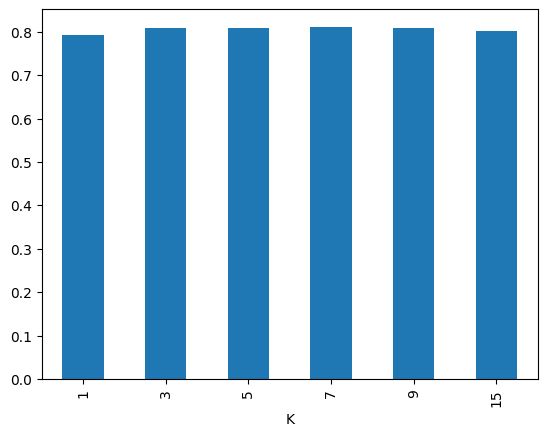

In [8]:
# Algorithm
# 1. Import the required libraries.
# 2. Load the Fashion-MNIST dataset.
# 3. Scale pixel values to the range 0 to 1.
# 4. Select a stratified subset of 12,000 images.
# 5. Split the data into training and testing sets.
# 6. Train KNN models using different K values.
# 7. Calculate accuracy and prediction time.
# 8. Select the K value with the highest accuracy.
# 9. Display the classification report.
# 10. Plot the accuracy comparison.

import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import *

data = fetch_openml('Fashion-MNIST', version=1, as_frame=False)
X, y = data.data / 255, data.target.astype(int)

X, _, y, _ = train_test_split(X, y, train_size=12000, stratify=y, random_state=42)
a, b, c, d = train_test_split(X, y, test_size=2000, stratify=y, random_state=42)

R = []
for k in [1, 3, 5, 7, 9, 15]:
    m = KNeighborsClassifier(n_neighbors=k, n_jobs=-1).fit(a, c)
    t = time.time()
    p = m.predict(b)
    R.append([k, accuracy_score(d, p), time.time() - t])

df = pd.DataFrame(R, columns=['K', 'Accuracy', 'Time'])
print(df)

k = int(df.loc[df.Accuracy.idxmax(), 'K'])
print("Best K:", k)
m = KNeighborsClassifier(n_neighbors=k, n_jobs=-1).fit(a, c)
print(classification_report(d, m.predict(b), zero_division=0))

df.set_index('K').Accuracy.plot.bar()
plt.show()
